# Clasificación de flores con redes neuronales convolucionales
## Notebook 1 de 2: datos y entrenamiento de los modelos

**Proyecto final – Electiva en Ingeniería de Software (redes neuronales)**
**Autor:** Juan Miguel López Rojas · **Docente:** Carlos Mario Paredes Valencia · Universidad de San Buenaventura Cali
**Repositorio:** https://github.com/DracoJM/clasificacion-flores-cnn

Este notebook descarga el conjunto de datos `tf_flowers`, lo divide en entrenamiento, validación y prueba, y entrena tres modelos:

| Modelo | Qué es | Para qué sirve en el proyecto |
|---|---|---|
| **CNN base** | Red convolucional de 4 bloques entrenada desde cero | Línea base: cuánto se logra sin conocimiento previo |
| **MobileNetV2 (avance 2)** | MobileNetV2 preentrenada en ImageNet, con la configuración del segundo avance | Referencia del problema: este modelo **presentaba sobreajuste** (overfitting) |
| **MobileNetV2 regularizada** | La misma red con las correcciones para reducir el sobreajuste. Se guarda en dos versiones: con la base congelada (fase 1) y con ajuste fino (fase 2) | **Modelo corregido del proyecto** |

El notebook 2 (`02_evaluacion_y_resultados.ipynb`) carga los modelos que se guardan aquí y calcula todas las métricas sobre el conjunto de prueba.

**Cómo ejecutarlo:** `Ejecutar todo`. Funciona en Google Colab o en un computador con Python 3.10+ y `pip install tensorflow scikit-learn matplotlib pandas`. En CPU tarda alrededor de hora y media; con GPU, unos minutos.

## 1. Librerías y configuración

In [1]:
import glob, json, os, random, time, urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split

SEMILLA = 42            # semilla fija para que la partición y los resultados se puedan repetir
IMG = 224               # tamaño de entrada de la red (224x224 píxeles)
LOTE = 32               # imágenes por lote
CLASES = ["dandelion", "daisy", "tulips", "sunflowers", "roses"]            # orden de etiquetas del dataset
CLASES_ES = ["Diente de león", "Margarita", "Tulipán", "Girasol", "Rosa"]

DATOS, MODELOS, RESULTADOS, FIGURAS = "datos", "modelos", "resultados", "resultados/figuras"
for carpeta in (DATOS, MODELOS, RESULTADOS, FIGURAS):
    os.makedirs(carpeta, exist_ok=True)

def fijar_semillas():
    random.seed(SEMILLA); np.random.seed(SEMILLA); tf.random.set_seed(SEMILLA)

plt.rcParams.update({"font.size": 10, "savefig.dpi": 200, "savefig.bbox": "tight"})
AZUL, NARANJA, VERDE, GRIS = "#2F6DB5", "#E07B39", "#3E8E41", "#7F7F7F"
print("TensorFlow", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU") or "no (se usa CPU)")

I0000 00:00:1794872960.401410    5995 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794872960.401870    5995 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794872960.453450    5995 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1794872961.532383    5995 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794872961.532746    5995 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow 2.21.0 | GPU: no (se usa CPU)


E0000 00:00:1794872962.229839    5995 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


## 2. Conjunto de datos `tf_flowers`

`tf_flowers` es un conjunto público del equipo de TensorFlow: **3.670 fotografías** de **5 especies** de flores tomadas de Flickr (licencia CC BY 2.0). Se descarga directamente del almacenamiento público de TensorFlow Datasets (dos archivos `.tfrecord`, 233 MB en total).

In [2]:
URL = "https://storage.googleapis.com/tfds-data/datasets/tf_flowers/3.0.1/"
ARCHIVOS = ["tf_flowers-train.tfrecord-00000-of-00002", "tf_flowers-train.tfrecord-00001-of-00002"]
for nombre in ARCHIVOS:
    destino = os.path.join(DATOS, nombre)
    if not os.path.exists(destino):
        print("Descargando", nombre, "...")
        urllib.request.urlretrieve(URL + nombre, destino)
    print(nombre, f"{os.path.getsize(destino)/1e6:.1f} MB")

tf_flowers-train.tfrecord-00000-of-00002 114.2 MB
tf_flowers-train.tfrecord-00001-of-00002 118.5 MB


In [3]:
def cargar_dataset(carpeta):
    """Lee los TFRecord, decodifica cada JPEG y lo redimensiona a 224x224."""
    archivos = sorted(glob.glob(os.path.join(carpeta, "*.tfrecord*")))
    formato = {"image": tf.io.FixedLenFeature([], tf.string),
               "label": tf.io.FixedLenFeature([], tf.int64)}
    X, y, tam = [], [], []
    for registro in tf.data.TFRecordDataset(archivos):
        ejemplo = tf.io.parse_single_example(registro, formato)
        img = tf.io.decode_jpeg(ejemplo["image"], channels=3)
        tam.append(img.shape[:2])                                   # tamaño original (alto, ancho)
        img = tf.image.resize(img, (IMG, IMG), antialias=True)
        X.append(tf.cast(tf.round(img), tf.uint8).numpy())
        y.append(int(ejemplo["label"]))
    return np.stack(X), np.array(y), np.array(tam)

X, y, tam = cargar_dataset(DATOS)
print("Imágenes:", X.shape, "| etiquetas:", y.shape)
print(f"Resolución original: alto {tam[:,0].min()}–{tam[:,0].max()} px, ancho {tam[:,1].min()}–{tam[:,1].max()} px, "
      f"mediana {int(np.median(tam[:,1]))}×{int(np.median(tam[:,0]))}")

I0000 00:00:1794872962.312252    6048 tf_record_dataset_op.cc:390] TFRecordDataset `buffer_size` is unspecified, default to 262144


Imágenes: (3670, 224, 224, 3) | etiquetas: (3670,)
Resolución original: alto 159–442 px, ancho 143–1024 px, mediana 320×240


### 2.1 Partición estratificada 70 / 15 / 15

Se separa una sola vez, con semilla fija, en **entrenamiento** (para ajustar los pesos), **validación** (para decidir cuándo parar y elegir la configuración) y **prueba** (solo para la evaluación final del notebook 2). *Estratificada* significa que cada parte conserva la misma proporción de cada especie.

In [4]:
X_ent, X_tmp, y_ent, y_tmp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEMILLA)
X_val, X_pru, y_val, y_pru = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEMILLA)

tabla = pd.DataFrame({"Total": np.bincount(y), "% del total": (np.bincount(y) / len(y) * 100).round(2),
                      "Entrenamiento": np.bincount(y_ent), "Validación": np.bincount(y_val),
                      "Prueba": np.bincount(y_pru)}, index=CLASES_ES)
tabla.loc["Total"] = tabla.sum().round(0)
info_datos = {
    "total": int(len(y)),
    "por_clase": {CLASES_ES[i]: int((y == i).sum()) for i in range(5)},
    "split": {"entrenamiento": len(y_ent), "validacion": len(y_val), "prueba": len(y_pru)},
    "split_por_clase": {n: {CLASES_ES[i]: int((s == i).sum()) for i in range(5)}
                        for n, s in (("entrenamiento", y_ent), ("validacion", y_val), ("prueba", y_pru))},
    "resolucion_original": {"alto_min": int(tam[:, 0].min()), "alto_max": int(tam[:, 0].max()),
                            "ancho_min": int(tam[:, 1].min()), "ancho_max": int(tam[:, 1].max()),
                            "alto_mediana": float(np.median(tam[:, 0])), "ancho_mediana": float(np.median(tam[:, 1]))},
}
json.dump(info_datos, open(os.path.join(RESULTADOS, "datos.json"), "w"), indent=1, ensure_ascii=False)
tabla

,Total,% del total,Entrenamiento,Validación,Prueba
Diente de león,898,24.47,629,134,135
Margarita,633,17.25,443,95,95
Tulipán,799,21.77,559,120,120
Girasol,699,19.05,489,105,105
Rosa,641,17.47,449,96,96
Total,3670,100.00,2569,550,551


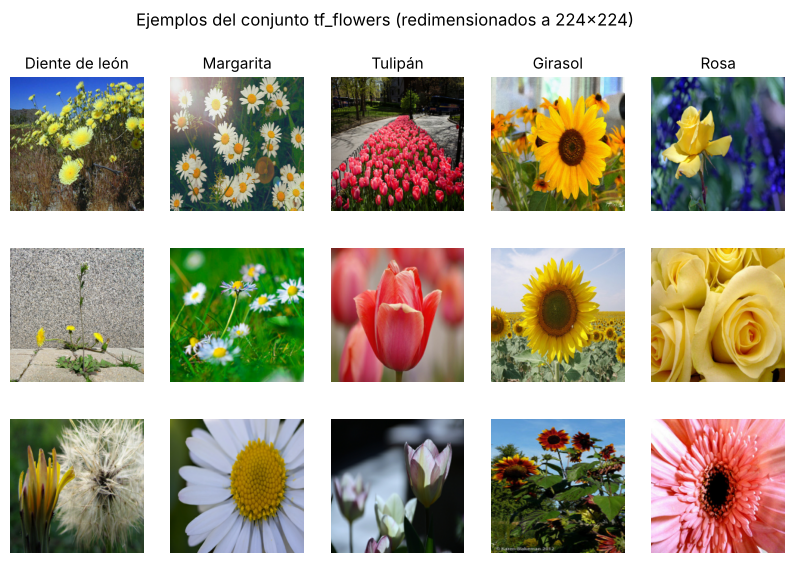

In [5]:
fig, ax = plt.subplots(3, 5, figsize=(10, 6.3))
rng = np.random.default_rng(0)
for c in range(5):
    for f, i in enumerate(rng.choice(np.where(y_ent == c)[0], 3, replace=False)):
        ax[f, c].imshow(X_ent[i]); ax[f, c].axis("off")
    ax[0, c].set_title(CLASES_ES[c], fontsize=11)
fig.suptitle("Ejemplos del conjunto tf_flowers (redimensionados a 224×224)", fontsize=12)
fig.savefig(os.path.join(FIGURAS, "fig01_muestras.png")); plt.show()

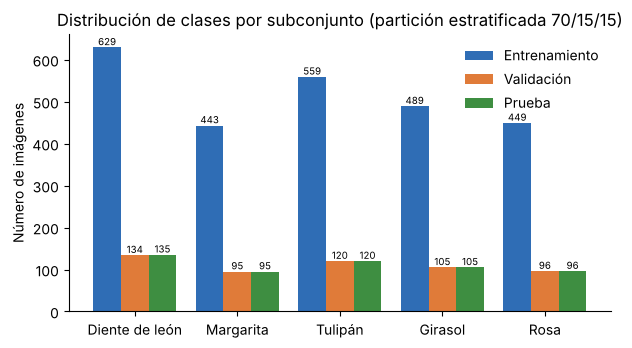

In [6]:
x = np.arange(5); w = 0.27
fig, ax = plt.subplots(figsize=(7, 3.6))
for k, (nombre, s, col) in enumerate((("Entrenamiento", y_ent, AZUL), ("Validación", y_val, NARANJA), ("Prueba", y_pru, VERDE))):
    barras = ax.bar(x + (k - 1) * w, np.bincount(s), w, label=nombre, color=col)
    ax.bar_label(barras, fontsize=7)
ax.set_xticks(x, CLASES_ES); ax.set_ylabel("Número de imágenes")
ax.set_title("Distribución de clases por subconjunto (partición estratificada 70/15/15)")
ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False)
fig.savefig(os.path.join(FIGURAS, "fig02_distribucion.png")); plt.show()

## 3. Aumento de datos (data augmentation)

El aumento de datos crea versiones ligeramente distintas de cada foto de entrenamiento (volteada, girada, ampliada, desplazada, con otro brillo o contraste). Así la red casi nunca ve dos veces exactamente la misma imagen y le cuesta más memorizarla. Solo actúa durante el entrenamiento; en validación y prueba las capas quedan desactivadas.

Se definen dos niveles:
- **suave:** el del segundo avance (volteo, rotación ±10 %, zoom ±10 %, contraste ±10 %).
- **fuerte:** el de esta entrega, pensado para reducir el sobreajuste (se amplía el zoom y el contraste y se agregan desplazamiento y brillo).

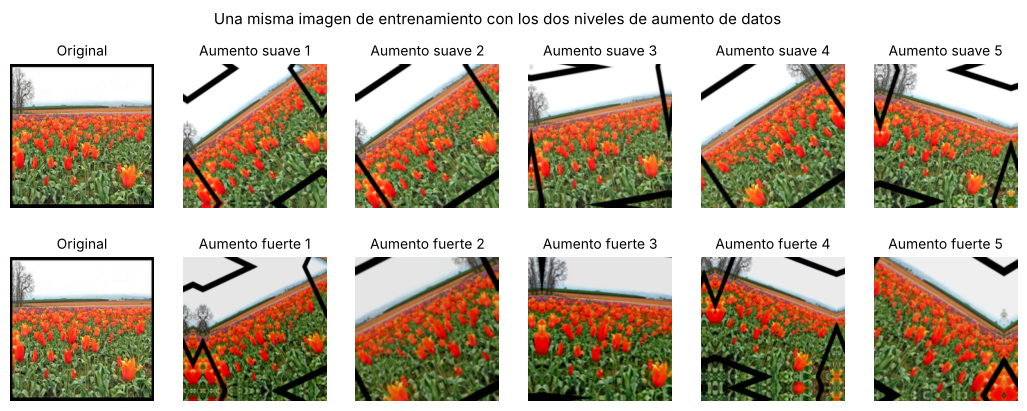

In [7]:
L = tf.keras.layers

def aumento(nivel):
    if nivel == "suave":
        capas = [L.RandomFlip("horizontal"), L.RandomRotation(0.1), L.RandomZoom(0.1), L.RandomContrast(0.1)]
    else:  # "fuerte"
        capas = [L.RandomFlip("horizontal"), L.RandomRotation(0.1), L.RandomZoom(0.2),
                 L.RandomTranslation(0.1, 0.1), L.RandomContrast(0.2),
                 L.RandomBrightness(0.1, value_range=(0, 255))]
    return tf.keras.Sequential(capas, name="aumento_" + nivel)

fijar_semillas()
fig, ax = plt.subplots(2, 6, figsize=(13, 4.6))
for fila, nivel in enumerate(("suave", "fuerte")):
    capa = aumento(nivel)
    ax[fila, 0].imshow(X_ent[3]); ax[fila, 0].set_title("Original", fontsize=10)
    for k in range(1, 6):
        img = capa(tf.cast(X_ent[3:4], tf.float32), training=True)[0]
        ax[fila, k].imshow(np.clip(img.numpy(), 0, 255).astype("uint8"))
        ax[fila, k].set_title(f"Aumento {nivel} {k}", fontsize=10)
for a in ax.ravel(): a.axis("off")
fig.suptitle("Una misma imagen de entrenamiento con los dos niveles de aumento de datos", fontsize=11)
fig.savefig(os.path.join(FIGURAS, "fig03_aumento.png")); plt.show()

## 4. Arquitecturas

**CNN base (desde cero).** Cuatro bloques `Conv 3×3 → BatchNorm → ReLU → MaxPool` con 32, 64, 128 y 256 filtros, promedio global (GAP), Dropout 0,3 y una capa densa softmax de 5 salidas.

**MobileNetV2 con transfer learning.** Se toma MobileNetV2 con los pesos de ImageNet, se le quita su clasificador de 1.000 clases y se le pone una cabeza nueva: GAP → Dropout → densa softmax de 5 salidas. La función recibe los tres elementos de regularización que se van a comparar: el nivel de aumento, la tasa de **Dropout** y el coeficiente de la penalización **L2** sobre la capa densa.

In [8]:
def crear_cnn_base():
    entrada = L.Input((IMG, IMG, 3))
    x = aumento("suave")(entrada)
    x = L.Rescaling(1.0 / 255)(x)                         # píxeles a [0, 1]
    for filtros in (32, 64, 128, 256):
        x = L.Conv2D(filtros, 3, padding="same", use_bias=False)(x)
        x = L.BatchNormalization()(x)
        x = L.ReLU()(x)
        x = L.MaxPooling2D()(x)
    x = L.GlobalAveragePooling2D()(x)
    x = L.Dropout(0.3)(x)
    salida = L.Dense(len(CLASES), activation="softmax")(x)
    return tf.keras.Model(entrada, salida, name="CNN_base")

def crear_mobilenet(nombre, nivel_aumento, dropout, l2):
    base = tf.keras.applications.MobileNetV2(input_shape=(IMG, IMG, 3), include_top=False, weights="imagenet")
    base.trainable = False                                # fase 1: toda la base congelada
    entrada = L.Input((IMG, IMG, 3))
    x = aumento(nivel_aumento)(entrada)
    x = L.Rescaling(1.0 / 127.5, offset=-1)(x)            # píxeles a [-1, 1], como espera MobileNetV2
    x = base(x, training=False)                           # BatchNorm de la base en modo inferencia
    x = L.GlobalAveragePooling2D()(x)
    x = L.Dropout(dropout)(x)
    regularizador = tf.keras.regularizers.l2(l2) if l2 else None
    salida = L.Dense(len(CLASES), activation="softmax", kernel_regularizer=regularizador)(x)
    return tf.keras.Model(entrada, salida, name=nombre), base

crear_cnn_base().summary()

Model: "CNN_base"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aumento_suave (Sequential)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 5)              │         1,285 │
└─────────────────────────────────┴────────────────────────┴─────────────

 Total params: 391,141 (1.49 MB)

 Trainable params: 390,181 (1.49 MB)

 Non-trainable params: 960 (3.75 KB)

In [9]:
modelo_tmp, base_tmp = crear_mobilenet("MobileNetV2_regularizada", "fuerte", 0.6, 0.005)
modelo_tmp.summary()
print("Capas de la base MobileNetV2:", len(base_tmp.layers))
del modelo_tmp, base_tmp

Model: "MobileNetV2_regularizada"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aumento_fuerte (Sequential)     │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │         6,405 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,264,389 (8.64 MB)

 Trainable params: 6,405 (25.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Capas de la base MobileNetV2: 154


## 5. Funciones de entrenamiento

- **Optimizador** Adam y **pérdida** de entropía cruzada categórica.
- **EarlyStopping:** si la pérdida de validación deja de mejorar, el entrenamiento se detiene y se recuperan los pesos de la mejor época.
- **ReduceLROnPlateau:** baja la tasa de aprendizaje a la mitad si la pérdida de validación se estanca 3 épocas.

Al terminar cada entrenamiento se mide la exactitud **sin aumento ni Dropout** sobre entrenamiento y validación. La diferencia entre las dos (*brecha de generalización*) es la medida de sobreajuste que se usa en todo el proyecto: si la red acierta mucho más en las imágenes con las que entrenó que en las que nunca vio, las está memorizando.

In [10]:
def a_dataset(X, y, barajar):
    d = tf.data.Dataset.from_tensor_slices((X, y))
    if barajar:
        d = d.shuffle(len(X), seed=SEMILLA, reshuffle_each_iteration=True)
    return d.map(lambda a, b: (tf.cast(a, tf.float32), b)).batch(LOTE).prefetch(tf.data.AUTOTUNE)

def controles(paciencia):
    return [tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=paciencia, restore_best_weights=True),
            tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6)]

def compilar(modelo, lr):
    modelo.compile(optimizer=tf.keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy", metrics=["accuracy"])

def unir_historias(*historias):
    union = {}
    for h in historias:
        for k, v in h.history.items():
            union.setdefault(k, []).extend(float(x) for x in v)
    return union

def medir(modelo, Xp, yp):
    """Exactitud y entropía cruzada (sin el término L2) con el modelo en modo inferencia."""
    prob = modelo.predict(a_dataset(Xp, yp, False), verbose=0)
    exactitud = float((prob.argmax(1) == yp).mean())
    perdida = float(-np.log(np.clip(prob[np.arange(len(yp)), yp], 1e-7, 1.0)).mean())
    return exactitud, perdida

def brecha(modelo):
    """Exactitud y pérdida sin aumento ni dropout en entrenamiento y validación."""
    (a_ent, p_ent), (a_val, p_val) = medir(modelo, X_ent, y_ent), medir(modelo, X_val, y_val)
    print(f"  Entrenamiento: exactitud {a_ent*100:.2f} %, pérdida {p_ent:.4f}")
    print(f"  Validación:    exactitud {a_val*100:.2f} %, pérdida {p_val:.4f}")
    print(f"  Brecha entrenamiento − validación: {(a_ent-a_val)*100:.2f} puntos")
    return {"acc_ent": a_ent, "acc_val": a_val, "loss_ent": p_ent, "loss_val": p_val}

def entrenar_mobilenet(nombre, nivel_aumento, dropout, l2, epocas_f1, capa_ft, epocas_f2, lr_f2=1e-5):
    """Fase 1: solo la cabeza nueva (lr 1e-3). Fase 2: ajuste fino desde la capa `capa_ft` (lr 1e-5)."""
    fijar_semillas()
    modelo, base = crear_mobilenet(nombre, nivel_aumento, dropout, l2)
    t0 = time.time()
    print(f"=== {nombre} · Fase 1: extracción de características (base congelada) ===")
    compilar(modelo, 1e-3)
    h1 = modelo.fit(a_dataset(X_ent, y_ent, True), validation_data=a_dataset(X_val, y_val, False),
                    epochs=epocas_f1, callbacks=controles(4), verbose=2)
    e1 = len(h1.history["loss"])
    print("Al terminar la fase 1 (pesos de la mejor época de validación):"); fin_f1 = brecha(modelo)
    modelo.save(os.path.join(MODELOS, nombre + "_fase1.keras"))       # versión con la base congelada
    t_f1 = time.time() - t0
    entrenables_f1 = int(sum(np.prod(w.shape) for w in modelo.trainable_weights))
    print(f"=== {nombre} · Fase 2: ajuste fino desde la capa {capa_ft} ===")
    base.trainable = True
    for i, capa in enumerate(base.layers):
        # Las BatchNorm quedan congeladas para conservar las estadísticas de ImageNet
        capa.trainable = i >= capa_ft and not isinstance(capa, L.BatchNormalization)
    compilar(modelo, lr_f2)
    h2 = modelo.fit(a_dataset(X_ent, y_ent, True), validation_data=a_dataset(X_val, y_val, False),
                    epochs=e1 + epocas_f2, initial_epoch=e1, callbacks=controles(4), verbose=2)
    historia = unir_historias(h1, h2)
    print("Al terminar la fase 2 (pesos de la mejor época de validación):"); fin = brecha(modelo)
    resumen = {"nombre": nombre, "aumento": nivel_aumento, "dropout": dropout, "l2": l2, "capa_ft": capa_ft,
               "capas_base": len(base.layers), "inicio_ft": e1,
               "epocas_f1": epocas_f1, "epocas_f2": epocas_f2, "lr_f2": lr_f2, "epocas": len(historia["loss"]),
               "tiempo_s": time.time() - t0, "tiempo_f1_s": t_f1, "fin_fase1": fin_f1, "final": fin,
               "parametros_entrenables_f1": entrenables_f1,
               "parametros": int(modelo.count_params()),
               "parametros_entrenables": int(sum(np.prod(w.shape) for w in modelo.trainable_weights))}
    modelo.save(os.path.join(MODELOS, nombre + ".keras"))
    return modelo, historia, resumen

historias, resumenes = {}, {}

## 6. Modelo A: CNN base entrenada desde cero

Hasta 40 épocas con tasa de aprendizaje 10⁻³ y paciencia de 8 épocas.

In [11]:
fijar_semillas()
cnn = crear_cnn_base()
compilar(cnn, 1e-3)
t0 = time.time()
h = cnn.fit(a_dataset(X_ent, y_ent, True), validation_data=a_dataset(X_val, y_val, False),
            epochs=40, callbacks=controles(8), verbose=2)
historias["CNN_base"] = unir_historias(h)
print("Al terminar (pesos de la mejor época de validación):")
resumenes["CNN_base"] = {"nombre": "CNN_base", "epocas": len(h.history["loss"]), "tiempo_s": time.time() - t0,
                         "final": brecha(cnn), "parametros": int(cnn.count_params()),
                         "parametros_entrenables": int(sum(np.prod(w.shape) for w in cnn.trainable_weights))}
cnn.save(os.path.join(MODELOS, "CNN_base.keras"))

Epoch 1/40


/home/claude/venv/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


81/81 - 81s - 1s/step - accuracy: 0.5158 - loss: 1.2590 - val_accuracy: 0.2436 - val_loss: 1.7434 - learning_rate: 0.0010


Epoch 2/40


81/81 - 91s - 1s/step - accuracy: 0.5858 - loss: 1.0825 - val_accuracy: 0.2436 - val_loss: 1.9701 - learning_rate: 0.0010


Epoch 3/40


... (73 outputs left out)

Epoch 40/40


81/81 - 57s - 705ms/step - accuracy: 0.8194 - loss: 0.4995 - val_accuracy: 0.8200 - val_loss: 0.5292 - learning_rate: 3.1250e-05


Al terminar (pesos de la mejor época de validación):


  Entrenamiento: exactitud 85.01 %, pérdida 0.4220
  Validación:    exactitud 82.00 %, pérdida 0.5292
  Brecha entrenamiento − validación: 3.01 puntos


## 7. Modelo B: MobileNetV2 con la configuración del segundo avance (sin corregir)

Es exactamente el modelo entregado en el avance 2: aumento suave, Dropout 0,2, sin L2 y ajuste fino de las capas 116 a 153 (bloques 13 a 16). Se vuelve a entrenar aquí para medir su sobreajuste con el mismo criterio que el modelo corregido.

In [12]:
_, historias["MobileNetV2_avance2"], resumenes["MobileNetV2_avance2"] = entrenar_mobilenet(
    "MobileNetV2_avance2", nivel_aumento="suave", dropout=0.2, l2=0.0, epocas_f1=10, capa_ft=116, epocas_f2=15)

=== MobileNetV2_avance2 · Fase 1: extracción de características (base congelada) ===


Epoch 1/10


81/81 - 25s - 309ms/step - accuracy: 0.6322 - loss: 0.9542 - val_accuracy: 0.8236 - val_loss: 0.5178 - learning_rate: 0.0010


Epoch 2/10


81/81 - 23s - 284ms/step - accuracy: 0.8244 - loss: 0.5053 - val_accuracy: 0.8618 - val_loss: 0.4234 - learning_rate: 0.0010


Epoch 3/10


... (46 outputs left out)

Epoch 25/25


81/81 - 24s - 295ms/step - accuracy: 0.9813 - loss: 0.0625 - val_accuracy: 0.9109 - val_loss: 0.2796 - learning_rate: 5.0000e-06


Al terminar la fase 2 (pesos de la mejor época de validación):


  Entrenamiento: exactitud 98.01 %, pérdida 0.0597
  Validación:    exactitud 91.27 %, pérdida 0.2688
  Brecha entrenamiento − validación: 6.74 puntos


## 8. Modelo C: MobileNetV2 regularizada

Correcciones contra el sobreajuste respecto al modelo B:

1. **Aumento de datos fuerte** (más zoom y contraste, y se agregan desplazamiento y brillo).
2. **Dropout 0,6** en lugar de 0,2 antes de la capa de salida.
3. **Regularización L2** (coeficiente 0,005) sobre los pesos de la capa densa.
4. Se mantiene la **detención temprana** con recuperación de la mejor época.

El entrenamiento tiene las mismas dos fases, y **se guarda el modelo al final de cada una**, porque el ajuste fino es el paso que más pesos libera y por tanto el que más puede sobreajustar:

- `MobileNetV2_regularizada_fase1.keras`: base congelada, solo se entrena la cabeza (6.405 pesos).
- `MobileNetV2_regularizada.keras`: después del ajuste fino de las capas 116 a 153 (bloques 13 a 16 y convolución final) con tasa de aprendizaje 5e-05.

Además de la regularización, cambian dos decisiones de optimización respecto al modelo B: la fase 1 dispone de hasta 25 épocas (en lugar de 10), porque con aumento fuerte y Dropout alto la cabeza aprende más despacio, y el ajuste fino usa una tasa de 5e-05 (en lugar de 1e-05). Por eso la comparación entre B y C mide el efecto conjunto de todos estos cambios, no el de una técnica aislada.

Estos valores se eligieron mirando únicamente el conjunto de **validación**; el conjunto de prueba no se usó para decidir nada.

In [13]:
_, historias["MobileNetV2_regularizada"], resumenes["MobileNetV2_regularizada"] = entrenar_mobilenet(
    "MobileNetV2_regularizada", nivel_aumento="fuerte", dropout=0.6, l2=0.005, epocas_f1=25, capa_ft=116, epocas_f2=15, lr_f2=5e-05)

=== MobileNetV2_regularizada · Fase 1: extracción de características (base congelada) ===


Epoch 1/25


81/81 - 26s - 324ms/step - accuracy: 0.4877 - loss: 1.4528 - val_accuracy: 0.8000 - val_loss: 0.6281 - learning_rate: 0.0010


Epoch 2/25


81/81 - 21s - 262ms/step - accuracy: 0.7248 - loss: 0.8060 - val_accuracy: 0.8582 - val_loss: 0.5010 - learning_rate: 0.0010


Epoch 3/25


... (56 outputs left out)

Epoch 30/35


81/81 - 25s - 312ms/step - accuracy: 0.9704 - loss: 0.1288 - val_accuracy: 0.9145 - val_loss: 0.3042 - learning_rate: 2.5000e-05


Al terminar la fase 2 (pesos de la mejor época de validación):


  Entrenamiento: exactitud 97.28 %, pérdida 0.0799
  Validación:    exactitud 91.82 %, pérdida 0.2378
  Brecha entrenamiento − validación: 5.46 puntos


## 9. Curvas de entrenamiento y comparación del sobreajuste

En las curvas, la línea discontinua es entrenamiento y la continua es validación. Cuando la curva de entrenamiento se separa hacia arriba (exactitud) o hacia abajo (pérdida) de la de validación, hay sobreajuste.

Nota: la exactitud de entrenamiento que Keras muestra en cada época se calcula **con** aumento y Dropout activos, por eso puede quedar por debajo de la de validación. La medida limpia es la de la tabla final. Además, en el modelo regularizado la pérdida de las curvas incluye el término L2 (igual en entrenamiento y validación); la tabla final reporta la entropía cruzada sola.

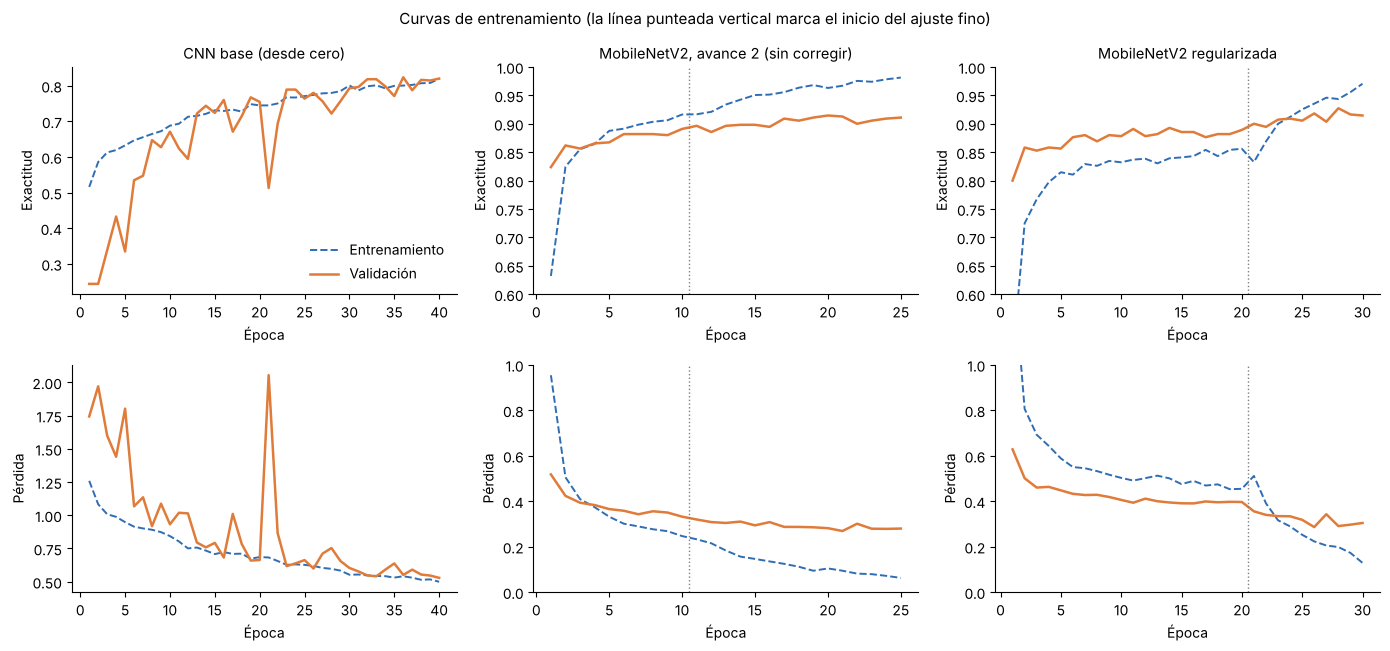

In [14]:
json.dump({"historias": historias, "resumenes": resumenes},
          open(os.path.join(RESULTADOS, "entrenamiento.json"), "w"), indent=1, ensure_ascii=False)

titulos = {"CNN_base": "CNN base (desde cero)", "MobileNetV2_avance2": "MobileNetV2, avance 2 (sin corregir)",
           "MobileNetV2_regularizada": "MobileNetV2 regularizada"}
fig, ax = plt.subplots(2, 3, figsize=(14, 6.6))
for k, nombre in enumerate(titulos):
    h = historias[nombre]; ep = np.arange(1, len(h["loss"]) + 1)
    for fila, (m, etiqueta) in enumerate((("accuracy", "Exactitud"), ("loss", "Pérdida"))):
        a = ax[fila, k]
        a.plot(ep, h[m], color=AZUL, ls="--", lw=1.4, label="Entrenamiento")
        a.plot(ep, h["val_" + m], color=NARANJA, lw=1.8, label="Validación")
        if "inicio_ft" in resumenes[nombre]:
            a.axvline(resumenes[nombre]["inicio_ft"] + 0.5, color=GRIS, ls=":", lw=1)
        a.set_xlabel("Época"); a.set_ylabel(etiqueta); a.spines[["top", "right"]].set_visible(False)
        if k > 0: a.set_ylim((0.6, 1.0) if m == "accuracy" else (0.0, 1.0))
    ax[0, k].set_title(titulos[nombre], fontsize=10.5)
ax[0, 0].legend(frameon=False)
fig.suptitle("Curvas de entrenamiento (la línea punteada vertical marca el inicio del ajuste fino)", fontsize=11)
fig.tight_layout(); fig.savefig(os.path.join(FIGURAS, "fig05_curvas.png")); plt.show()

In [15]:
filas = []
versiones = [("CNN base (desde cero)", resumenes["CNN_base"], "final", "epocas", "tiempo_s")]
for nombre, etiqueta in (("MobileNetV2_avance2", "MobileNetV2 avance 2"), ("MobileNetV2_regularizada", "MobileNetV2 regularizada")):
    versiones.append((etiqueta + ", base congelada (fase 1)", resumenes[nombre], "fin_fase1", "inicio_ft", "tiempo_f1_s"))
    versiones.append((etiqueta + ", con ajuste fino (fase 2)", resumenes[nombre], "final", "epocas", "tiempo_s"))
for etiqueta, r, clave, clave_ep, clave_t in versiones:
    f = r[clave]
    filas.append({"Modelo": etiqueta, "Épocas": r[clave_ep], "Tiempo (min)": round(r[clave_t] / 60, 1),
                  "Exactitud entrenamiento (%)": round(f["acc_ent"] * 100, 2),
                  "Exactitud validación (%)": round(f["acc_val"] * 100, 2),
                  "Brecha (puntos)": round((f["acc_ent"] - f["acc_val"]) * 100, 2),
                  "Pérdida entrenamiento": round(f["loss_ent"], 4), "Pérdida validación": round(f["loss_val"], 4)})
pd.DataFrame(filas).set_index("Modelo")

,Épocas,Tiempo (min),Exactitud entrenamiento (%),Exactitud validación (%),Brecha (puntos),Pérdida entrenamiento,Pérdida validación
Modelo,,,,,,,
CNN base (desde cero),40,44.4,85.01,82.00,3.01,0.4220,0.5292
"MobileNetV2 avance 2, base congelada (fase 1)",10,4.8,93.66,89.09,4.56,0.1988,0.3320
"MobileNetV2 avance 2, con ajuste fino (fase 2)",25,12.3,98.01,91.27,6.74,0.0597,0.2688
"MobileNetV2 regularizada, base congelada (fase 1)",20,9.6,91.32,88.55,2.77,0.2610,0.3411
"MobileNetV2 regularizada, con ajuste fino (fase 2)",30,14.6,97.28,91.82,5.46,0.0799,0.2378


**Lectura.** La tabla anterior es el resultado central de este notebook: compara la brecha entre entrenamiento y validación del modelo del avance 2 con la del modelo regularizado, al final de cada fase (las épocas y el tiempo de la fase 2 son acumulados). Los modelos quedan guardados en la carpeta `modelos/` y el historial en `resultados/entrenamiento.json`. La evaluación sobre el conjunto de prueba se hace en el notebook 2.